# JupyerLab notebook example for UPENN like simulations

/!\ /!\ /!\  
Oxygen diffusion from cell environment not (yet) included in the model.  
Therefore, the oxygen level is reinitialized before each new pulse.  

## Module imports

In [1]:
# External modules (to "pip install")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Modules from Standard lib
from pathlib import Path

# RadioBio module
import radiopyo as rp

## Simulation Run

**1) Load configuration from the toml file +**  
 -> create a ref to O2 species for later use  
 -> define the desired number of pulses  
 -> define the period

In [2]:
file = Path(rf"configuration_UPENN.toml")
uc = rp.UnitCell.from_toml(file)

O2 = uc.env.species.get("O2")
PULSES_NUMBER = 3
PERIOD = 120 # seconds

2023-05-23 17:08:49,633::radiopyo::INFO::Loading config from TOML file: configuration_UPENN.toml
2023-05-23 17:08:49,641::radiopyo::INFO::File is loaded
2023-05-23 17:08:49,641::radiopyo::INFO::Beam configuration detected in config file
2023-05-23 17:08:49,642::radiopyo::INFO::Beam SinglePulseBeam(dose_rate=3e+02, max_dose=30.0, start_time=0.0) is setup
2023-05-23 17:08:49,643::radiopyo::INFO::CONFIG::Configuring Simulation Environment
2023-05-23 17:08:49,643::radiopyo::INFO::CONFIG::3 Acid/Base reactions added
2023-05-23 17:08:49,645::radiopyo::INFO::CONFIG::38 K-reactions added
2023-05-23 17:08:49,645::radiopyo::INFO::CONFIG::1 Enzymatic reactions added
2023-05-23 17:08:49,646::radiopyo::INFO::CONFIG::6 Radiolytic reactions added
2023-05-23 17:08:49,647::radiopyo::INFO::CONFIG::19 Dynamical Species added.
2023-05-23 17:08:49,647::radiopyo::INFO::CONFIG::9 Constant Species added.
2023-05-23 17:08:49,648::radiopyo::INFO::CONFIG::Simulation Configuration done!
2023-05-23 17:08:49,667::r

**2) Run sim over the first pulse**

In [3]:
res = uc.prepare_chunked_run([1e-9, PERIOD],
                             max_step_size_on=1e-5,
                             max_step_size_off=0.5).run()

2023-05-23 17:08:52,407::radiopyo::INFO::Simulation divided in 2 chunks
2023-05-23 17:08:52,409::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-05-23 17:08:57,172::radiopyo::INFO::Simulation done!


**3) Run the next pulses**
* Reset beam start time  
* Copy final concentrations of previous sim  
* Reset the O2 concentration to its initial value (in µmol/L)  
* Run and append the simulation result to the previous result  

In [4]:
for pulse in range(PULSES_NUMBER-1):
    uc.beam.reset(start=res.time[-1])
    y0 = res.final_cc
    y0[O2.index] = O2.initial_cc()*1e6
    res +=  uc.prepare_chunked_run([res.time[-1], res.time[-1]+PERIOD],
                                   max_step_size_on=1e-5,
                                   max_step_size_off=0.5,
                                   y0=y0).run()

2023-05-23 17:08:59,774::radiopyo::INFO::Simulation divided in 2 chunks
2023-05-23 17:08:59,777::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-05-23 17:09:05,416::radiopyo::INFO::Simulation done!
2023-05-23 17:09:05,419::radiopyo::INFO::Simulation divided in 2 chunks
2023-05-23 17:09:05,422::radiopyo::INFO::Running all simulation chunks


  0%|          | 0/2 [00:00<?, ?it/s]

2023-05-23 17:09:08,735::radiopyo::INFO::Simulation done!


**Convert final result to pandas DataFrame**

In [5]:
df = res.to_pandas()

In [13]:
res.integrate_species()

OH_r                 1.409017e-08
O_r_minus            3.069536e-10
H2O2                 6.746245e-01
HO2_minus            1.345791e-05
HO2_r                1.610344e-03
O2_r_minus           1.580608e-02
e_aq                 9.701503e-08
H_r                  4.784557e-08
H2                   1.138884e+03
O2                   1.666400e+04
O2_minus_minus       3.506827e-03
O3_minus             6.322818e-03
Fe_plus_plus_plus    1.440028e-01
RH_r                 4.626895e+03
R_r                  7.368092e-03
ROO_r                2.642992e+02
ROH                  7.614840e+02
RO                   7.614840e+02
ROOH                 1.167458e+00
dtype: float64

## Results usage

**Integrate values per pulse**

In [21]:
res.n_points

[13715, 1766, 16492, 897, 12238, 1033]

In [16]:
by_pulse = pd.DataFrame(columns=df.columns)
for pulse in range(PULSES_NUMBER):
    by_pulse.loc[pulse, :] = res.integrate_species(start=pulse*PERIOD, stop=(pulse+1)*PERIOD)

In [17]:
by_pulse

,OH_r,O_r_minus,H2O2,HO2_minus,HO2_r,O2_r_minus,e_aq,H_r,H2,O2,O2_minus_minus,O3_minus,Fe_plus_plus_plus,RH_r,R_r,ROO_r,ROH,RO,ROOH
0,0.0,0.0,0.224872,0.000004,0.00004,0.005268,0.0,0.0,189.639201,5550.264714,0.000584,0.0001,0.023968,770.414159,0.002456,87.980701,122.086114,122.086114,0.177478
1,0.0,0.0,0.224877,0.000004,0.000045,0.005269,0.0,0.0,379.562226,5553.927981,0.001169,0.000279,0.047993,1541.980953,0.002456,88.157973,253.766015,253.766015,0.389062
2,0.0,0.0,0.224877,0.000004,0.001521,0.005267,0.0,0.0,568.049501,5540.873623,0.001749,0.005929,0.071836,2307.867176,0.002456,88.153081,384.501648,384.501648,0.599101


### Plot

In [45]:
# Some common plot options for uniformity
RIGHT_LIMIT = 1e3

#### Water-only Radiolytic produced species

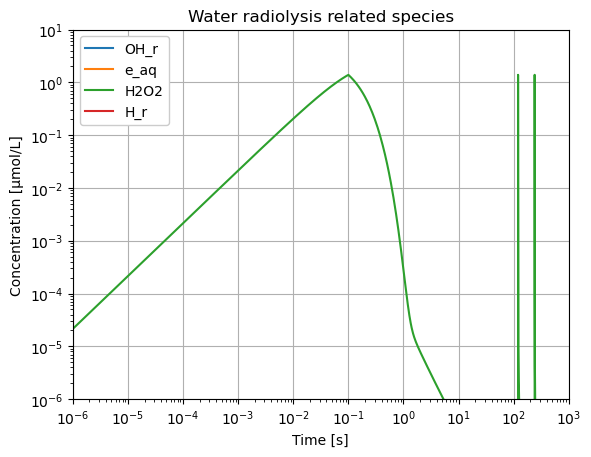

In [40]:
G_species = ["OH_r", "e_aq", "H2O2", "H_r"]
fig, ax = plt.subplots()
for label in G_species:
    ax.plot(df.index, df[label], label=label, marker="")

ax.set_ylim(bottom=1e-6, top=10)
ax.set_xlim([1e-6, RIGHT_LIMIT])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Concentration [µmol/L]")
ax.legend(fancybox=True, framealpha=1)
ax.set_title("Water radiolysis related species")
ax.grid()

#### Biology related species

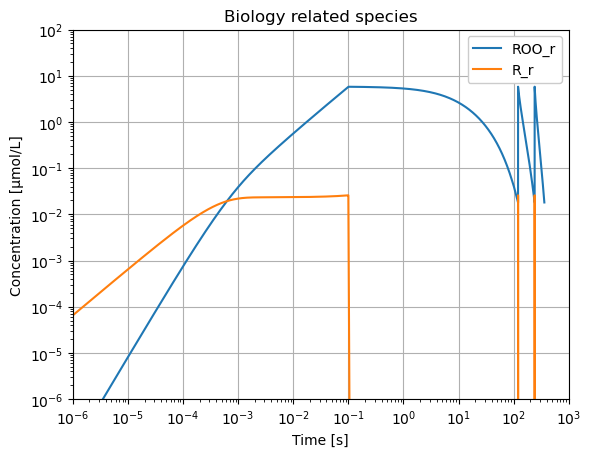

In [41]:
G_species = ["ROO_r", "R_r"]
fig, ax = plt.subplots()
for label in G_species:
    ax.plot(df.index, df[label], label=label, marker="")

ax.set_ylim(bottom=1e-6, top=100)
ax.set_xlim([1e-6, RIGHT_LIMIT])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Concentration [µmol/L]")
ax.legend(fancybox=True, framealpha=1)
ax.set_title("Biology related species")
ax.grid()

#### O2

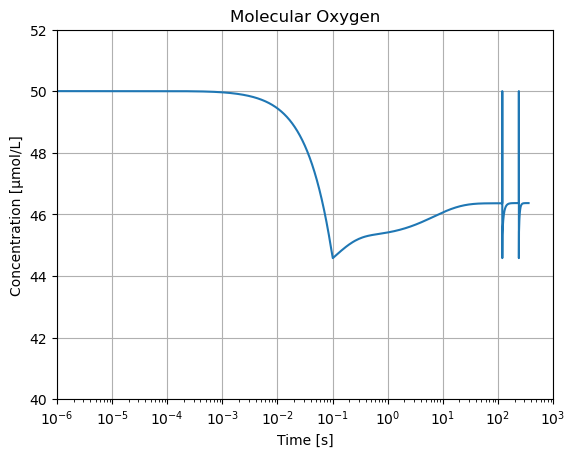

In [42]:
G_species = ["O2"]
fig, ax = plt.subplots()
for label in G_species:
    ax.plot(df.index, df[label], label=label, marker="")

ax.set_ylim(bottom=40, top=52)
ax.set_xlim([1e-6, RIGHT_LIMIT])
ax.set_xscale("log")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Concentration [µmol/L]")
ax.set_title("Molecular Oxygen")
ax.grid()